In [1]:
import pandas as pd
df = pd.read_csv("data_jobs_raw.csv")

In [2]:
print(df.shape)
df.dtypes

(785741, 17)


job_title_short              str
job_title                    str
job_location                 str
job_via                      str
job_schedule_type            str
job_work_from_home          bool
search_location              str
job_posted_date              str
job_no_degree_mention       bool
job_health_insurance        bool
job_country                  str
salary_rate                  str
salary_year_avg          float64
salary_hour_avg          float64
company_name                 str
job_skills                   str
job_type_skills              str
dtype: object

In [12]:
(df.isna().mean() * 100).round(1).sort_values(ascending=False)

salary_hour_avg          98.6
salary_year_avg          97.2
salary_rate              95.8
job_type_skills          14.9
job_skills               14.9
job_schedule_type         1.6
job_location              0.1
job_title_short           0.0
job_title                 0.0
job_no_degree_mention     0.0
job_posted_date           0.0
search_location           0.0
job_work_from_home        0.0
job_via                   0.0
job_country               0.0
job_health_insurance      0.0
company_name              0.0
dtype: float64

In [13]:
df["job_title_short"].value_counts()

job_title_short
Data Analyst                 196075
Data Engineer                186241
Data Scientist               172286
Business Analyst              49063
Software Engineer             44929
Senior Data Engineer          44563
Senior Data Scientist         36957
Senior Data Analyst           29216
Machine Learning Engineer     14080
Cloud Engineer                12331
Name: count, dtype: int64

In [17]:
print(df.shape)

df["job_country"].value_counts().head(10)

(785741, 17)


job_country
United States     206292
India              51088
United Kingdom     40375
France             39922
Germany            27694
Spain              25100
Singapore          23696
Sudan              21781
Netherlands        20631
Italy              17013
Name: count, dtype: int64

In [21]:
##is malaysia is in the data?
print((df["job_country"] == "Malaysia").sum())

# is there anything wrong with Sudan data?
df[df["job_country"] == "Sudan"][["job_title_short", "job_location", "search_location", "job_via"]].sample(10, random_state=1)

# 3. Roles (I still need this one)
df["job_title_short"].value_counts()

9219


job_title_short
Data Analyst                 196075
Data Engineer                186241
Data Scientist               172286
Business Analyst              49063
Software Engineer             44929
Senior Data Engineer          44563
Senior Data Scientist         36957
Senior Data Analyst           29216
Machine Learning Engineer     14080
Cloud Engineer                12331
Name: count, dtype: int64

In [22]:
df[df["job_country"] == "Sudan"][["job_title_short", "job_location", "search_location", "job_via"]].sample(10, random_state=1)

,job_title_short,job_location,search_location,job_via
458343,Senior Data Engineer,United States,Sudan,via SimplyHired
199604,Senior Data Scientist,"Phoenix, AZ",Sudan,via Indeed
379715,Data Analyst,"Englewood, CO",Sudan,via LinkedIn
297453,Data Scientist,"Houston, TX",Sudan,via LinkedIn
558874,Data Scientist,"Arlington, TX",Sudan,via BeBee
530220,Senior Data Engineer,"San Francisco, CA",Sudan,via Wellfound
688830,Senior Data Analyst,Anywhere,Sudan,via LinkedIn
727354,Data Scientist,Anywhere,Sudan,via Indeed
336351,Data Scientist,"Addison, TX",Sudan,"via Addison, TX - Geebo"
711205,Data Engineer,Anywhere,Sudan,via ZipRecruiter


In [43]:
sudan = df[df["job_country"] == "Sudan"]

# What do the real locations look like?
print(sudan["job_location"].value_counts().head(15))

# Share that are "Anywhere" or end in a US state code like ", TX"
is_anywhere = sudan["job_location"].eq("Anywhere")
is_us_style = sudan["job_location"].str.contains(r", [A-Z]{2}$", na=False)
print("Anywhere:", round(is_anywhere.mean() * 100, 1), "%")
print("US-style:", round(is_us_style.mean() * 100, 1), "%")



job_location
Anywhere           3930
United States      2497
Dallas, TX          836
Austin, TX          808
Albuquerque, NM     783
Houston, TX         743
Santa Fe, NM        591
Texas               569
Phoenix, AZ         363
Denver, CO          352
Irving, TX          348
Plano, TX           331
New York, NY        274
Arlington, TX       243
Lubbock, TX         210
Name: count, dtype: int64
Anywhere: 18.0 %
US-style: 66.2 %


In [44]:
df["us_style"] = df["job_location"].str.contains(r", [A-Z]{2}$", na=False)

check = (
    df[df["job_country"] != "United States"]
    .groupby("job_country")["us_style"]
    .mean()
    .mul(100).round(1)
    .sort_values(ascending=False)
)
print(check.head(15))


job_country
United Kingdom    76.0
Sudan             66.2
Afghanistan        0.0
Angola             0.0
Argentina          0.0
Albania            0.0
Algeria            0.0
Austria            0.0
Azerbaijan         0.0
Bahamas            0.0
Bahrain            0.0
Bangladesh         0.0
Barbados           0.0
Armenia            0.0
Australia          0.0
Name: us_style, dtype: float64


In [47]:
print("Rows:", len(df))
print("Duplicate rows:", df.duplicated().sum())

Rows: 785640
Duplicate rows: 0


In [46]:
df = df.drop_duplicates()

In [48]:
df["job_posted_date"] = pd.to_datetime(df["job_posted_date"])

In [49]:
import ast
df["job_skills"] = df["job_skills"].apply(
    lambda x: ast.literal_eval(x) if pd.notna(x) else x
)

In [2]:
df_clean = df[df["job_country"] != "Sudan"].copy()
print("Removed:", len(df) - len(df_clean), "rows")
len(df)

Removed: 21781 rows


785741

In [52]:
uk = df[df["job_country"] == "United Kingdom"]
print(uk["job_location"].value_counts().head(10))
print("Ends with ', UK':", round(uk["job_location"].str.endswith(", UK").mean() * 100, 1), "%")

job_location
London, UK        10564
United Kingdom     5317
Anywhere           3764
England, UK        1815
Manchester, UK     1742
Leeds, UK          1040
Birmingham, UK     1033
Edinburgh, UK       797
Bristol, UK         574
Glasgow, UK         520
Name: count, dtype: int64
Ends with ', UK': 76.0 %


In [53]:
print((df["job_country"] == "Malaysia").sum())
df["job_title_short"].value_counts()

9218


job_title_short
Data Analyst                 196050
Data Engineer                186216
Data Scientist               172263
Business Analyst              49053
Software Engineer             44918
Senior Data Engineer          44561
Senior Data Scientist         36955
Senior Data Analyst           29214
Machine Learning Engineer     14079
Cloud Engineer                12331
Name: count, dtype: int64

In [54]:
my = df[df["job_country"] == "Malaysia"]
my["job_location"].value_counts().head(10)

job_location
Kuala Lumpur, Federal Territory of Kuala Lumpur, Malaysia    5071
Malaysia                                                     1188
Petaling Jaya, Selangor, Malaysia                             763
George Town, Penang, Malaysia                                 334
Cyberjaya, Selangor, Malaysia                                 246
Shah Alam, Selangor, Malaysia                                 170
Anywhere                                                      158
Subang Jaya, Selangor, Malaysia                               127
Selangor, Malaysia                                            121
Bayan Lepas, Penang, Malaysia                                 103
Name: count, dtype: int64

In [119]:
da = df_clean[df_clean["job_title_short"] == "Data Analyst"]

da_skills = da.explode("job_skills")

top_skills = (
    da_skills["job_skills"]
    .value_counts()
    .head(10)
)
print(top_skills)

job_skills
sql           91565
excel         66252
python        56670
tableau       46006
power bi      39106
r             29690
sas           27582
powerpoint    13656
word          13342
sap           11203
Name: count, dtype: int64


In [82]:
total_da = len(da.dropna(subset=["job_skills"]))
(top_skills / total_da * 100).round(1)

job_skills
sql           58.0
excel         41.9
python        35.9
tableau       29.1
power bi      24.8
r             18.8
sas           17.5
powerpoint     8.6
word           8.4
sap            7.1
Name: count, dtype: float64

In [116]:
#top skill for Malaysia 
da_my = da[da["job_country"] == "Malaysia"]
my_skills = da_my.explode("job_skills")["job_skills"].value_counts().head(10)
total_my = len(da_my.dropna(subset=["job_skills"]))
(my_skills / total_my * 100).round(1)

job_skills
sql           54.0
excel         50.4
python        36.4
tableau       28.9
power bi      26.5
sas           18.7
r             17.4
sap           12.1
powerpoint     9.5
word           7.8
Name: count, dtype: float64

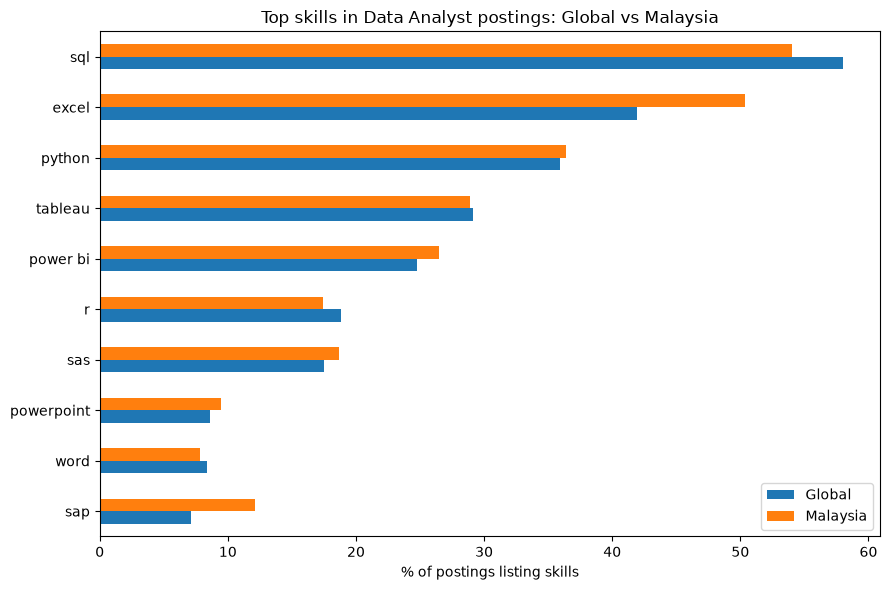

In [108]:
import matplotlib.pyplot as plt

global_pct = (top_skills / total_da * 100).round(1)
my_pct = (my_skills / total_my * 100).round(1)

compare = pd.DataFrame({"Global": global_pct, "Malaysia": my_pct}).fillna(0)
compare = compare.sort_values("Global", ascending=True)
compare

compare.plot(kind="barh", figsize=(9, 6))
plt.title("Top skills in Data Analyst postings: Global vs Malaysia")
plt.xlabel("% of postings listing skills")
plt.ylabel("")
plt.tight_layout()
plt.savefig("da_skills_global_vs_malaysia.png", dpi=150)
plt.show()

In [24]:
##Question 2: how do skills differ across the three roles?

roles = ["Data Analyst", "Data Engineer", "Data Scientist"]

sub = df_clean[df_clean["job_title_short"].isin(roles)].dropna(subset=["job_skills"])
totals = sub.groupby("job_title_short").size()
totals

exploded = sub.explode("job_skills")
counts = (
    exploded.groupby(["job_title_short", "job_skills"])
    .size()
    .reset_index(name="n")
)

counts["pct"] = counts["n"] / counts["job_title_short"].map(totals) * 100

counts["pct"]




0         0.000633
1         0.001266
2         0.001266
3         0.000633
4         0.000633
            ...   
132046    0.000723
132047    0.150327
132048    0.000723
132049    0.000723
132050    0.028909
Name: pct, Length: 132051, dtype: float64

In [155]:
counts

,job_title_short,job_skills,n,pct
0,Data Analyst,airflow,1993,1.261832
1,Data Analyst,airtable,88,0.055716
2,Data Analyst,alteryx,4515,2.858590
3,Data Analyst,angular,368,0.232992
4,Data Analyst,angular.js,2,0.001266
...,...,...,...,...
706,Data Scientist,wrike,8,0.005782
707,Data Scientist,wsl,31,0.022406
708,Data Scientist,xamarin,5,0.003614
709,Data Scientist,yarn,241,0.174191


In [173]:
top = counts.sort_values("pct", ascending=False).groupby("job_title_short").head(10)
skills_union = top["job_skills"].unique()
skills_union


pivot = (
    counts[counts["job_skills"].isin(skills_union)]
    .pivot(index="job_skills", columns="job_title_short", values="pivot_value" if False else "pct")
    .fillna(0)
    .round(2)
    .sort_values("Data Analyst", ascending=False)
)
pivot

job_title_short,Data Analyst,Data Engineer,Data Scientist
job_skills,,,
sql,57.97,66.65,53.98
excel,41.95,5.00,11.98
python,35.88,63.64,77.75
tableau,29.13,10.97,20.04
power bi,24.76,11.18,10.88
r,18.80,7.41,40.46
sas,17.46,4.39,19.87
powerpoint,8.65,0.72,3.26
word,8.45,1.96,3.51


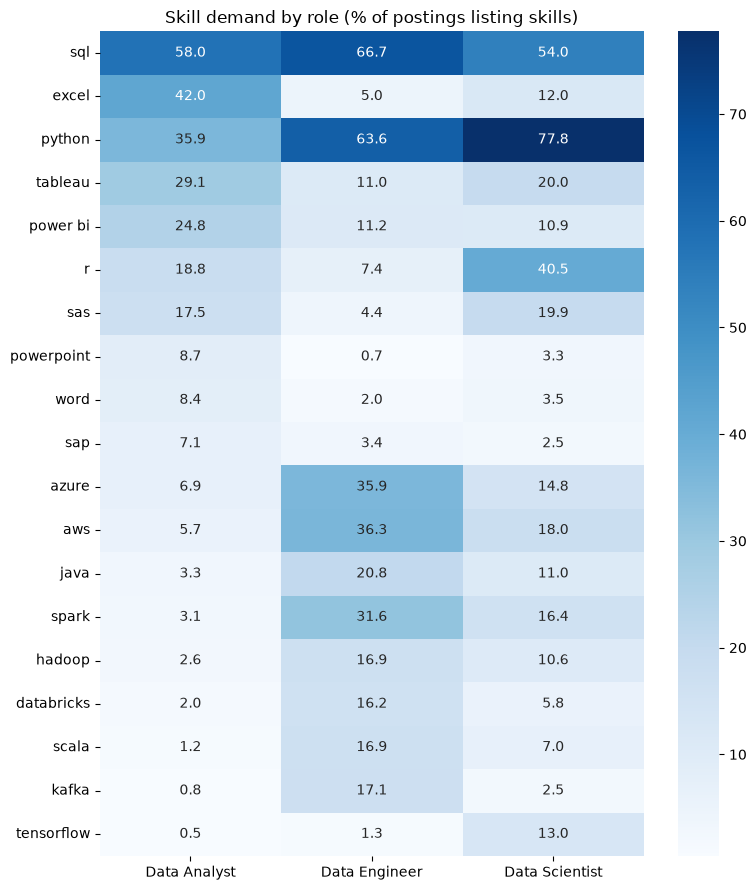

In [177]:
import seaborn as sns
import matplotlib.pyplot as plt

plt.figure(figsize=(8, 9))
sns.heatmap(pivot, annot=True, fmt=".1f", cmap="Blues")
plt.title("Skill demand by role (% of postings listing skills)")
plt.ylabel("")
plt.xlabel("")
plt.tight_layout()
plt.savefig("skills_by_role_heatmap.png", dpi=150)
plt.show()

In [13]:
##skills and salary
da_sal = df_clean[df_clean["job_title_short"] == "Data Analyst"].dropna(
    subset=["salary_year_avg", "job_skills"]
)
print("Analyst postings with salary + skills:", len(da_sal))
print(da_sal["job_country"].value_counts().head(5))

##since US count is very high, it show salary findings describe the US market most of other countries info on salary is missing.(3% only)



Analyst postings with salary + skills: 4735
job_country
United States     3868
India               86
United Kingdom      65
France              47
Poland              40
Name: count, dtype: int64


In [14]:
exploded = da_sal.explode("job_skills")

stats = (
    exploded.groupby("job_skills")["salary_year_avg"]
    .agg(count="count", median="median")
)

stats = stats[stats["count"] >= 50].sort_values("median", ascending=False)
stats.head(15).round(0)

##Why median: a few very high salaries can pull the average up, and the median is more robust.
##Why the count filter: a skill with 3 salaried postings can look "highly paid" by chance, so we require at least 50.

,count,median
job_skills,,
"['sql', 'excel']",106,90000.0
"['sql', 'python']",52,89100.0
['sql'],139,80000.0
['excel'],192,70000.0


In [6]:
##Demad over time
print(df_clean["job_posted_date"].min())
print(df_clean["job_posted_date"].max())

2023-01-01 00:00:04
2023-12-31 23:59:58


In [4]:
core = df_clean[df_clean["job_title_short"].isin(
    ["Data Analyst", "Data Engineer", "Data Scientist"]
)]



In [5]:
core["job_posted_date"] = pd.to_datetime(core["job_posted_date"], errors="coerce")

In [6]:
monthly = (
    core.groupby([core["job_posted_date"].dt.to_period("M"), "job_title_short"])
    .size()
    .unstack()
)

In [26]:
monthly

job_title_short,Data Analyst,Data Engineer,Data Scientist
job_posted_date,,,
2023-01,23277,20926,19834
2023-02,16371,15380,13132
2023-03,16063,15531,12817
2023-04,15372,14419,12671
2023-05,13340,13103,10995
2023-06,15927,14912,12929
2023-07,16017,14000,13587
2023-08,18495,15044,16144
2023-09,14825,14418,12884


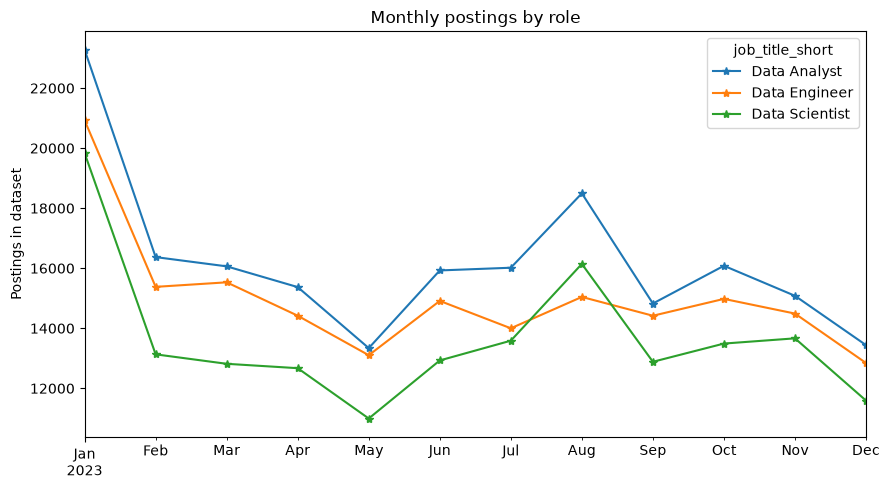

In [21]:
import matplotlib.pyplot as plt

monthly.plot(figsize=(9, 5), marker="*")
plt.title("Monthly postings by role")
plt.xlabel("")
plt.ylabel("Postings in dataset")
plt.tight_layout()
plt.savefig("monthly_postings_by_role.png", dpi=150)
plt.show()

In [ ]:
#remote work and degree requirements

roles = ["Data Analyst", "Data Engineer", "Data Scientist"]
core = df_clean[df_clean["job_title_short"].isin(roles)]

summary = (
    core.groupby("job_title_short")[
        ["job_work_from_home", "job_no_degree_mention", "job_health_insurance"]
    ]
    .mean().mul(100).round(1)
)
summary

In [ ]:
summary = (
    core.groupby("job_title_short")[
        ["job_work_from_home", "job_no_degree_mention", "job_health_insurance"]
    ]
    .mean().mul(100).round(1)
)
summary

,job_work_from_home,job_no_degree_mention,job_health_insurance
job_title_short,,,
Data Analyst,6.7,38.8,12.4
Data Engineer,11.2,44.0,6.6
Data Scientist,7.9,6.2,14.1


In [22]:
core_my = core[core["job_country"] == "Malaysia"]
print("Malaysia core-role postings:", len(core_my))

summary_my = (
    core_my.groupby("job_title_short")[
        ["job_work_from_home", "job_no_degree_mention", "job_health_insurance"]
    ]
    .mean().mul(100).round(1)
)
summary_my

Malaysia core-role postings: 5422


,job_work_from_home,job_no_degree_mention,job_health_insurance
job_title_short,,,
Data Analyst,1.6,32.3,0.0
Data Engineer,2.7,36.9,0.0
Data Scientist,1.5,8.9,0.0


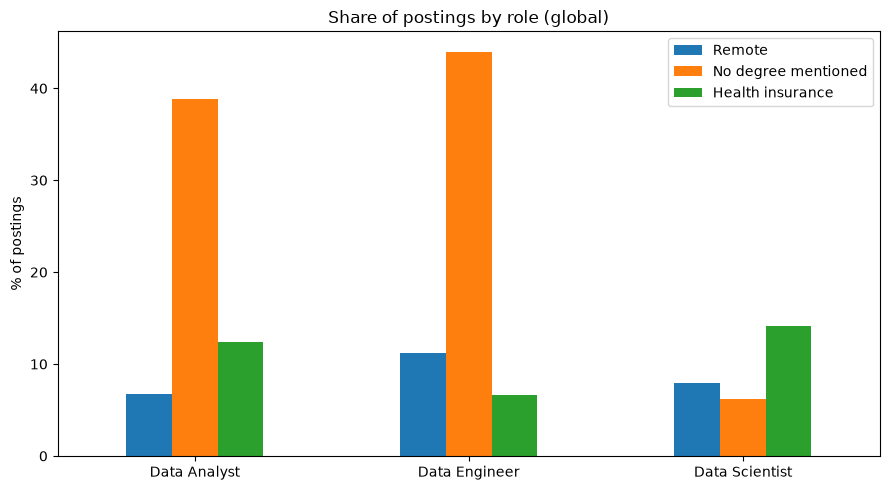

In [40]:
import matplotlib.pyplot as plt

summary.plot(kind="bar", figsize=(9, 5))
plt.title("Share of postings by role (global)")
plt.ylabel("% of postings")
plt.xlabel("")
plt.xticks(rotation=0)
plt.legend(["Remote", "No degree mentioned", "Health insurance"])
plt.tight_layout()
plt.savefig("remote_degree_by_role.png", dpi=150)
plt.show()

In [5]:
import sqlite3

jobs = df_clean.drop(columns=["job_skills", "job_type_skills", "us_style"], errors="ignore").copy()
jobs["job_id"] = jobs.index
jobs["job_posted_date"] = pd.to_datetime(
    jobs["job_posted_date"], errors="coerce"
).dt.strftime("%Y-%m-%d %H:%M:%S")

import ast

skills = (
    df_clean[["job_skills"]]
    .dropna()
    .assign(job_skills=lambda d: d["job_skills"].apply(ast.literal_eval))
    .explode("job_skills")
    .rename(columns={"job_skills": "skill"})
    .rename_axis("job_id")
    .reset_index()
)

In [28]:
type(df_clean["job_skills"].iloc[1])

str

In [6]:
skills

,job_id,skill
0,1,r
1,1,python
2,1,sql
3,1,nosql
4,1,power bi
...,...,...
3534502,785737,excel
3534503,785738,powerpoint
3534504,785738,excel
3534505,785740,aws


In [7]:
jobs

,job_title_short,job_title,job_location,job_via,job_schedule_type,job_work_from_home,search_location,job_posted_date,job_no_degree_mention,job_health_insurance,job_country,salary_rate,salary_year_avg,salary_hour_avg,company_name,job_id
0,Senior Data Engineer,Senior Clinical Data Engineer / Principal Clin...,"Watertown, CT",via Work Nearby,Full-time,False,"Texas, United States",2023-06-16 13:44:15,False,False,United States,NaN,NaN,NaN,Boehringer Ingelheim,0
1,Data Analyst,Data Analyst,"Guadalajara, Jalisco, Mexico",via BeBee México,Full-time,False,Mexico,2023-01-14 13:18:07,False,False,Mexico,NaN,NaN,NaN,Hewlett Packard Enterprise,1
2,Data Engineer,"Data Engineer/Scientist/Analyst, Mid or Senior...","Berlin, Germany",via LinkedIn,Full-time,False,Germany,2023-10-10 13:14:55,False,False,Germany,NaN,NaN,NaN,ALPHA Augmented Services,2
3,Data Engineer,LEAD ENGINEER - PRINCIPAL ANALYST - PRINCIPAL ...,"San Antonio, TX",via Diversity.com,Full-time,False,"Texas, United States",2023-07-04 13:01:41,True,False,United States,NaN,NaN,NaN,Southwest Research Institute,3
5,Data Engineer,GCP Data Engineer,Anywhere,via ZipRecruiter,Contractor and Temp work,True,Georgia,2023-11-07 14:01:59,False,False,United States,NaN,NaN,NaN,smart folks inc,5
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
785735,Senior Data Engineer,Senior Data Engineer,"Berlin, Jerman",melalui Top County Careers,Pekerjaan tetap,False,Germany,2023-03-13 06:19:07,False,False,Germany,NaN,NaN,NaN,Pure App,785735
785736,Software Engineer,DevOps Engineer,Singapura,melalui Trabajo.org,Pekerjaan tetap,False,Singapore,2023-03-13 06:16:16,False,False,Singapore,NaN,NaN,NaN,CAREERSTAR INTERNATIONAL PTE. LTD.,785736
785737,Data Analyst,CRM Data Analyst,"Bad Rodach, Jerman",melalui BeBee Deutschland,Pekerjaan tetap,False,Germany,2023-03-12 06:18:18,False,False,Germany,NaN,NaN,NaN,HABA FAMILYGROUP,785737
785738,Business Analyst,Commercial Analyst - Start Now,Malaysia,melalui Ricebowl,Pekerjaan tetap,False,Malaysia,2023-03-12 06:32:36,False,False,Malaysia,NaN,NaN,NaN,Lendlease Corporation,785738


In [9]:
conn = sqlite3.connect("jobs.db")
jobs.to_sql("jobs", conn, if_exists="replace", index=False, chunksize=50000)
skills.to_sql("job_skills", conn, if_exists="replace", index=False, chunksize=50000)
conn.execute("CREATE INDEX idx_skills_job ON job_skills(job_id)")
conn.execute("CREATE INDEX idx_jobs_id ON jobs(job_id)")
conn.commit()

In [10]:
##top Data Analyst skills (matching [andas result])

query = """
WITH da AS (
    SELECT DISTINCT j.job_id
    FROM jobs j
    JOIN job_skills s ON s.job_id = j.job_id
    WHERE j.job_title_short = 'Data Analyst'
)
SELECT s.skill,
       COUNT(*) AS postings,
       ROUND(100.0 * COUNT(*) / (SELECT COUNT(*) FROM da), 1) AS pct
FROM job_skills s
JOIN jobs j ON j.job_id = s.job_id
WHERE j.job_title_short = 'Data Analyst'
GROUP BY s.skill
ORDER BY postings DESC
LIMIT 10;
"""
pd.read_sql(query, conn)

## cross checked result in two ways

,skill,postings,pct
0,sql,91571,58.0
1,excel,66254,41.9
2,python,56674,35.9
3,tableau,46008,29.1
4,power bi,39108,24.8
5,r,29691,18.8
6,sas,27584,17.5
7,powerpoint,13656,8.6
8,word,13342,8.4
9,sap,11203,7.1


In [11]:
##top 5 skills per role, using a CTE and a window function


query = """
WITH role_skill AS (
    SELECT j.job_title_short AS role, s.skill, COUNT(*) AS n
    FROM jobs j
    JOIN job_skills s ON s.job_id = j.job_id
    WHERE j.job_title_short IN ('Data Analyst', 'Data Engineer', 'Data Scientist')
    GROUP BY j.job_title_short, s.skill
),
ranked AS (
    SELECT role, skill, n,
           RANK() OVER (PARTITION BY role ORDER BY n DESC) AS rnk
    FROM role_skill
)
SELECT role, rnk, skill, n
FROM ranked
WHERE rnk <= 5
ORDER BY role, rnk;
"""
pd.read_sql(query, conn)



,role,rnk,skill,n
0,Data Analyst,1,sql,91571
1,Data Analyst,2,excel,66254
2,Data Analyst,3,python,56674
3,Data Analyst,4,tableau,46008
4,Data Analyst,5,power bi,39108
5,Data Engineer,1,sql,108938
6,Data Engineer,2,python,104025
7,Data Engineer,3,aws,59373
8,Data Engineer,4,azure,58717
9,Data Engineer,5,spark,51648


In [12]:
query = """
SELECT s.skill,
       COUNT(*) AS postings,
       ROUND(AVG(j.salary_year_avg), 0) AS avg_salary
FROM jobs j
JOIN job_skills s ON s.job_id = j.job_id
WHERE j.job_title_short = 'Data Analyst'
  AND j.job_country = 'United States'
  AND j.salary_year_avg IS NOT NULL
GROUP BY s.skill
HAVING COUNT(*) >= 50
ORDER BY avg_salary DESC
LIMIT 10;
"""
pd.read_sql(query, conn)

,skill,postings,avg_salary
0,spark,94,115967.0
1,databricks,62,115341.0
2,pandas,59,114967.0
3,hadoop,97,113858.0
4,express,74,113796.0
5,snowflake,195,112211.0
6,jira,116,108533.0
7,alteryx,106,107760.0
8,redshift,65,107509.0
9,looker,166,107504.0


In [28]:
import os
import ast

os.makedirs("dashboard", exist_ok=True)


roles = ["Data Analyst", "Data Engineer", "Data Scientist"]
base = df_clean[df_clean["job_title_short"].isin(roles)].dropna(subset=["job_skills"])


def skill_table(data, scope):
    totals = data.groupby("job_title_short").size().rename("total_postings")
    out = (
        data.assign(
            job_skills=lambda d: d["job_skills"].apply(
                lambda value: ast.literal_eval(value)
                if isinstance(value, str)
                else value
            )
        )
        .explode("job_skills")
        .groupby(["job_title_short", "job_skills"]).size()
        .rename("postings").reset_index()
        .merge(totals, on="job_title_short")
    )
    out["pct"] = (out["postings"] / out["total_postings"] * 100).round(1)
    out["scope"] = scope
    return out


skills_dash = pd.concat([
    skill_table(base, "Global"),
    skill_table(base[base["job_country"] == "Malaysia"], "Malaysia"),
])
skills_dash = skills_dash[skills_dash["postings"] >= 50]
#skills_dash.to_csv("dashboard/skills_by_role.csv", index=False)

In [29]:
skills_dash

,job_title_short,job_skills,postings,total_postings,pct,scope
0,Data Analyst,airflow,1994,157954,1.3,Global
1,Data Analyst,airtable,88,157954,0.1,Global
2,Data Analyst,alteryx,4515,157954,2.9,Global
3,Data Analyst,angular,368,157954,0.2,Global
5,Data Analyst,ansible,186,157954,0.1,Global
...,...,...,...,...,...,...
378,Data Scientist,shell,54,1225,4.4,Malaysia
381,Data Scientist,spark,198,1225,16.2,Malaysia
385,Data Scientist,sql,671,1225,54.8,Malaysia
392,Data Scientist,tableau,293,1225,23.9,Malaysia


In [ ]:
# Monthly trend
monthly_long = monthly.reset_index().melt(
    id_vars="job_posted_date", var_name="role", value_name="postings"
)
monthly_long["month"] = monthly_long["job_posted_date"].astype(str) + "-01"
monthly_long.drop(columns="job_posted_date").to_csv("dashboard/monthly_postings.csv", index=False)

,job_posted_date,role,postings,month
0,2023-01,Data Analyst,23277,2023-01-01
1,2023-02,Data Analyst,16371,2023-02-01
2,2023-03,Data Analyst,16063,2023-03-01
3,2023-04,Data Analyst,15372,2023-04-01
4,2023-05,Data Analyst,13340,2023-05-01
5,2023-06,Data Analyst,15927,2023-06-01
6,2023-07,Data Analyst,16017,2023-07-01
7,2023-08,Data Analyst,18495,2023-08-01
8,2023-09,Data Analyst,14825,2023-09-01
9,2023-10,Data Analyst,16082,2023-10-01


In [ ]:
monthly      

job_title_short,Data Analyst,Data Engineer,Data Scientist
job_posted_date,,,
2023-01,23277,20926,19834
2023-02,16371,15380,13132
2023-03,16063,15531,12817
2023-04,15372,14419,12671
2023-05,13340,13103,10995
2023-06,15927,14912,12929
2023-07,16017,14000,13587
2023-08,18495,15044,16144
2023-09,14825,14418,12884


In [21]:
# US analyst salary by skill (deduplicated)
import ast
us = df_clean[
    (df_clean["job_title_short"] == "Data Analyst")
    & (df_clean["job_country"] == "United States")
].dropna(subset=["salary_year_avg", "job_skills"])

us_dedup = us.drop_duplicates(subset=["job_title", "company_name", "salary_year_avg"])

salary_dash = (
    us_dedup.assign(
        job_skills=lambda d: d["job_skills"].apply(
            lambda value: ast.literal_eval(value)
            if isinstance(value, str)
            else value
        )
    ).explode("job_skills")
    .groupby("job_skills")["salary_year_avg"]
    .agg(postings="count", median_salary="median")
    .reset_index()
)
salary_dash = salary_dash[salary_dash["postings"] >= 50]
#salary_dash.to_csv("dashboard/us_analyst_salary_by_skill.csv", index=False)
print(len(us), "->", len(us_dedup), "after dedup")
salary_dash.sort_values("median_salary", ascending=False).head(10)

3868 -> 3493 after dedup


,job_skills,postings,median_salary
31,databricks,56,112500.000000
56,hadoop,81,111175.000000
129,snowflake,184,110707.554688
131,spark,89,110000.000000
42,express,64,109000.000000
95,pandas,53,106562.500000
2,alteryx,99,106562.500000
71,looker,153,105000.000000
63,jira,102,104802.500000
113,redshift,62,102250.000000


In [ ]:
# Remote / degree (leaving out health insurance, since it's a US artifact)
cols = ["job_work_from_home", "job_no_degree_mention"]

core = df_clean[df_clean["job_title_short"].isin(roles)]
rd = pd.concat([    
    core.groupby("job_title_short")[cols].mean().mul(100).round(1).assign(scope="Global"),
    core[core["job_country"] == "Malaysia"].groupby("job_title_short")[cols].mean().mul(100).round(1).assign(scope="Malaysia"),
]).reset_index()
rd.to_csv("dashboard/remote_degree.csv", index=False)
rd

,job_title_short,job_work_from_home,job_no_degree_mention,scope
0,Data Analyst,6.7,38.8,Global
1,Data Engineer,11.2,44.0,Global
2,Data Scientist,7.9,6.2,Global
3,Data Analyst,1.6,32.3,Malaysia
4,Data Engineer,2.7,36.9,Malaysia
5,Data Scientist,1.5,8.9,Malaysia
